In [ ]:
!pip install bitblas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.7/81.7 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.0/82.0 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.7/40.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 74.7 MB/s eta 0:00:00


In [ ]:
## Restart Runtime Here ##



In [ ]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
import kagglehub
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision.datasets import ImageFolder
from PIL import Image
from sklearn.model_selection import train_test_split


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using {device} device")


# Download latest version of ImageNet100
path = kagglehub.dataset_download("ambityga/imagenet100")
print("Path to dataset files:", path)

BATCH_SIZE = 128

from torchvision.transforms import RandAugment
from timm.data.auto_augment import rand_augment_transform

# augmentations
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    rand_augment_transform('rand-m9-mstd0.5', {}),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25)
])

transform_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class MergedImageFolder(Dataset):
    def __init__(self, roots, transform=None):
        all_classes = set()
        for root in roots:
            all_classes.update(os.listdir(root))
        self.classes = sorted(all_classes)
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

        self.samples = []
        for root in roots:
            for cls in os.listdir(root):
                cls_idx = self.class_to_idx[cls]
                cls_dir = os.path.join(root, cls)
                for img in os.listdir(cls_dir):
                    self.samples.append((os.path.join(cls_dir, img), cls_idx))

        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

# training dataset with augmentation
train_dataset = MergedImageFolder([
    f'{path}/train.X1',
    f'{path}/train.X2',
    f'{path}/train.X3',
    f'{path}/train.X4'
], transform=transform_train)

# test dataset with val transforms (no augmentation)
test_dataset_no_aug = MergedImageFolder([
    f'{path}/train.X1',
    f'{path}/train.X2',
    f'{path}/train.X3',
    f'{path}/train.X4'
], transform=transform_val)

# stratified split
targets = [sample[1] for sample in train_dataset.samples]
train_indices, test_indices = train_test_split(
    range(len(train_dataset)),
    test_size=5000,
    stratify=targets,
    random_state=42
)

from torch.utils.data import Subset
train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset_no_aug, test_indices)


val_dataset = ImageFolder(f'{path}/val.X', transform=transform_val)


train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)

print(f"Training samples: {len(train_subset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_subset)}")



using cuda device
Using Colab cache for faster access to the 'imagenet100' dataset.
Path to dataset files: /kaggle/input/imagenet100
Training samples: 125000
Validation samples: 5000
Test samples: 5000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

def RMSNorm(x, eps=1e-5):
    return x / torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + eps)

def activation_quant(x):
  scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
  y = (x * scale).round().clamp_(-128,127) / scale
  return y

def weight_quant(w):
  scale = 1.0 / w.abs().mean().clamp_(min=1e-5)
  u = (w * scale).round().clamp_(-1,1) / scale
  return u



class BitLinear(nn.Linear):
    def forward(self, x):
        w = self.weight
        x_quant = x + (activation_quant(x) - x).detach()
        w_quant = w + (weight_quant(w) - w).detach()
        y = F.linear(x_quant, w_quant, self.bias)
        return y


In [ ]:
import bitblas

print("Compiling BitBLAS operators...")
bitblas_matmuls = {}
unique_shapes = [(576, 192), (192, 192), (768, 192), (192, 768), (112, 192)]
m_values = [256, 128]

for (n, k) in unique_shapes:
    bitblas_matmuls[(n, k)] = {}
    for m in m_values:
        print(f"Compiling M={m}, N={n}, K={k}...")
        config = bitblas.MatmulConfig(
            M=m, N=n, K=k,
            A_dtype="int8", W_dtype="int2",
            accum_dtype="int32", out_dtype="float32",
        )
        bitblas_matmuls[(n, k)][m] = bitblas.Matmul(config=config)
        print(f"  Done")

print("All operators compiled successfully")

# reference correctness checks
print("\nRunning reference tests...")
for (n, k) in unique_shapes:
    for m in m_values:
        test = bitblas_matmuls[(n, k)][m]
        inp = torch.randint(-128, 127, (m, k), dtype=torch.int8).cuda()
        w = torch.randint(-1, 2, (n, k), dtype=torch.int8).cuda()
        out = test(inp.contiguous(), test.transform_weight(w).contiguous())
        ref = torch.matmul(inp.float(), w.float().t())
        max_diff = (out.float() - ref.float()).abs().max()
        try:
            torch.testing.assert_close(out.float(), ref.float(), rtol=1e-2, atol=1.0)
            print(f"M={m}, N={n}, K={k}: ✅ max_diff={max_diff:.4f}")
        except AssertionError:
            print(f"M={m}, N={n}, K={k}: ❌ max_diff={max_diff:.4f}")

Compiling BitBLAS operators...
Compiling M=256, N=576, K=192...
2026-07-16 01:58:50 [BitBLAS:ERROR]: An exception occurred for hint {block_M=16,block_N=16,warp_M=16,warp_N=16,block_K=192,threads=32,num_stages=2,enable_rasterization=False,split_k_factor=1}: Traceback (most recent call last):
  77: tvm::runtime::PackedFuncObj::Extractor<tvm::runtime::PackedFuncSubObj<tvm::runtime::TypedPackedFunc<tvm::IRModule (tvm::transform::Pass, tvm::IRModule)>::AssignTypedLambda<tvm::transform::__mk_TVM9::{lambda(tvm::transform::Pass, tvm::IRModule)#1}>(tvm::transform::__mk_TVM9::{lambda(tvm::transform::Pass, tvm::IRModule)#1}, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >)::{lambda(tvm::runtime::TVMArgs const&, tvm::runtime::T	...	3: tvm::tl::LayoutInferencer::VisitStmt_(tvm::tir::ForNode const*)
  2: tvm::tl::PartitionLoop(tvm::tir::For, tvm::tir::Var, tvm::arith::Analyzer*, tvm::tl::Fragment)
  1: tvm::tl::FragmentNode::Inverse() const
  0: tvm::tl::LayoutNode::I

In [ ]:

class BitLinearKernel(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.matmuls = bitblas_matmuls.get((out_features, in_features), {})

        # get a reference matmul to call transform_weight
        self.ref_matmul = next(iter(self.matmuls.values())) if self.matmuls else None

        # weight stored in BitBLAS transformed format
        self.weight = nn.Parameter(
            torch.zeros(out_features, in_features // 4, dtype=torch.int8),
            requires_grad=False)

        self.weight_scale = nn.Parameter(
            torch.ones(1, dtype=torch.float32), requires_grad=False)

        if bias:
            self.bias = nn.Parameter(torch.zeros(out_features), requires_grad=False)
        else:
            self.bias = None

    def quant_input(self, input):
        s = 127 / input.abs().max(dim=-1, keepdim=True).values.clamp(min=1e-5)
        return (input * s).round().clamp(-128, 127).to(torch.int8), s

    def forward(self, input):
        original_shape = input.shape
        if input.dim() == 3:
            input = input.reshape(-1, input.shape[-1])

        input, s = self.quant_input(input)
        M = input.shape[0]
        ret = torch.zeros(M, self.out_features, dtype=torch.float32, device=input.device)

        chunk_size = 256
        for i in range(0, M, chunk_size):
            chunk_input = input[i:i+chunk_size].contiguous()
            chunk_s = s[i:i+chunk_size].contiguous()
            chunk_M = chunk_input.shape[0]

            if chunk_M in self.matmuls:
                out = self.matmuls[chunk_M](chunk_input, self.weight)
            else:
                next_m = min(m for m in self.matmuls.keys() if m >= chunk_M)
                pad_size = next_m - chunk_M
                chunk_padded = torch.cat([chunk_input, chunk_input[:pad_size]], dim=0)
                out = self.matmuls[next_m](chunk_padded, self.weight)
                out = out[:chunk_M]

            # Dequantization
            out = out.float() * self.weight_scale / chunk_s
            ret[i:i+chunk_M] = out

        if self.bias is not None:
            ret = ret + self.bias.to(ret.dtype)

        ret = ret.reshape(*original_shape[:-1], self.out_features)
        return ret



In [ ]:

import timm
import types

def new_forward(self, x, attn_mask=None, is_causal=False):
    x = self.forward_features(x, attn_mask=attn_mask, is_causal=is_causal)
    x = self.forward_head(x)
    return x[:, :100]



In [ ]:
#Train the baseline model

from tqdm import tqdm
import time
import numpy as np
import random

NUM_RUNS = 3
NUM_EPOCHS = 15
LEARNING_RATE = 1e-4

all_histories = []
run_times_baseline = []
run_final_accs_baseline = []

for run in range(NUM_RUNS):
    torch.manual_seed(run)
    torch.cuda.manual_seed(run)

    # reinitialize model from pretrained weights each run
    model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    model.head = nn.Linear(192, 112, bias=True)
    model.forward = types.MethodType(new_forward, model)
    model = model.to(device)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()
            loss = loss_fn(output, labels)
            train_loss += loss.detach()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)
                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Run {run+1} Epoch {i+1}/{NUM_EPOCHS}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}')

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    run_times_baseline.append(run_time)
    run_final_accs_baseline.append(val_acc)
    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_time:.2f}s")
    print(f"  Final val accuracy: {val_acc:.4f}")

    torch.save(model.state_dict(), f'/content/baseline_run{run}.pth')

print(f"\n{'='*40}")
print(f"BASELINE TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time: {np.mean(run_times_baseline):.2f}s ± {np.std(run_times_baseline):.2f}s")
print(f"Final val accuracy: {np.mean(run_final_accs_baseline):.4f} ± {np.std(run_final_accs_baseline):.4f}")



Run 1/3 Epoch 1/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.91it/s]


Run 1 Epoch 1/15: Train Loss=4.3273, Train Acc=0.0485, Val Loss=3.8927, Val Acc=0.1080


Run 1/3 Epoch 2/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.19it/s]


Run 1 Epoch 2/15: Train Loss=4.0329, Train Acc=0.0897, Val Loss=3.6020, Val Acc=0.1660


Run 1/3 Epoch 3/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.18it/s]


Run 1 Epoch 3/15: Train Loss=3.8588, Train Acc=0.1180, Val Loss=3.4085, Val Acc=0.2000


... (80 outputs left out)

Run 3/3 Epoch 14/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.73it/s]


Run 3 Epoch 14/15: Train Loss=3.0746, Train Acc=0.2615, Val Loss=2.5289, Val Acc=0.3676


Run 3/3 Epoch 15/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.19it/s]


Run 3 Epoch 15/15: Train Loss=3.0230, Train Acc=0.2710, Val Loss=2.4976, Val Acc=0.3758

Run 3 results:
  Time: 3303.32s
  Final val accuracy: 0.3758

BASELINE TRAINING SUMMARY (3 runs)
Training time: 3304.36s ± 2.62s
Final val accuracy: 0.3799 ± 0.0031


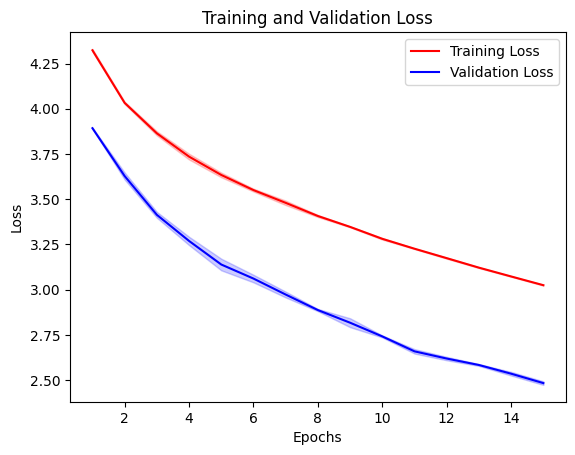

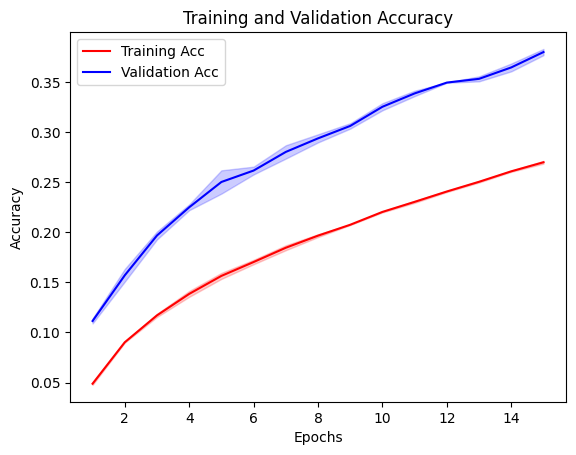

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/vit_baseline_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/vit_baseline_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
shutil.copy('/content/vit_baseline_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_baseline_loss_plot.pdf')
shutil.copy('/content/vit_baseline_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_baseline_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_baseline_accuracy_plot.pdf'

In [ ]:
def warmup_gpu(model, dataloader, num_batches=5):
    model.eval()
    with torch.no_grad():
        for i, (batch, _) in enumerate(dataloader):
            if i >= num_batches:
                break
            batch = batch.to(device)
            _ = model(batch)
    torch.cuda.synchronize() # ensures that warmup completes before training and timing begins.
    print(f"GPU warmup complete ({num_batches} batches)")

In [ ]:
#baseline inference
import time
from tqdm import tqdm
import numpy as np
loss_fn = torch.nn.CrossEntropyLoss()

NUM_EVAL_RUNS = 3

eval_times_baseline = []
eval_losses_baseline = []
eval_accs_baseline = []
eval_latencies_baseline = []
eval_throughputs_baseline = []

for run in range(NUM_EVAL_RUNS):
    baseline_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    baseline_model.head = nn.Linear(192, 112, bias=True)
    baseline_model.forward = types.MethodType(new_forward, baseline_model)
    baseline_model.load_state_dict(torch.load(f'/content/baseline_run{run}.pth'))
    baseline_model = baseline_model.to(device)
    baseline_model.eval()

    if run == 0:
        warmup_gpu(baseline_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Baseline Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_baseline.append(run_time)
    eval_losses_baseline.append(test_loss / len(test_loader))
    eval_accs_baseline.append(test_correct_predictions / test_total)
    eval_latencies_baseline.append(run_time / len(test_loader) * 1000)
    eval_throughputs_baseline.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_baseline[-1]:.4f}, Accuracy={eval_accs_baseline[-1]:.4f}, Latency={eval_latencies_baseline[-1]:.2f}ms, Throughput={eval_throughputs_baseline[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BASELINE INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_baseline):.2f}s ± {np.std(eval_times_baseline):.2f}s")
print(f"Loss:       {np.mean(eval_losses_baseline):.4f} ± {np.std(eval_losses_baseline):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_baseline):.4f} ± {np.std(eval_accs_baseline):.4f}")
print(f"Latency:    {np.mean(eval_latencies_baseline):.2f}ms ± {np.std(eval_latencies_baseline):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_baseline):.2f} ± {np.std(eval_throughputs_baseline):.2f} samples/s")

GPU warmup complete (5 batches)


Baseline Testing run 1/3: 100%|██████████| 40/40 [00:09<00:00,  4.39it/s]


Run 1: Time=9.11s, Loss=2.3056, Accuracy=0.4120, Latency=227.67ms, Throughput=549.05 samples/s


Baseline Testing run 2/3: 100%|██████████| 40/40 [00:05<00:00,  7.07it/s]


Run 2: Time=5.66s, Loss=2.3131, Accuracy=0.4170, Latency=141.50ms, Throughput=883.37 samples/s


Baseline Testing run 3/3: 100%|██████████| 40/40 [00:05<00:00,  6.89it/s]

Run 3: Time=5.81s, Loss=2.3287, Accuracy=0.4170, Latency=145.27ms, Throughput=860.45 samples/s

BASELINE INFERENCE SUMMARY (3 runs)
Time:       6.86s ± 1.59s
Loss:       2.3158 ± 0.0096
Accuracy:   0.4153 ± 0.0024
Latency:    171.48ms ± 39.76ms
Throughput: 764.29 ± 152.49 samples/s


In [ ]:
#Train the bitlinear model
from tqdm import tqdm
import time
import numpy as np
import random


# NUM_EPOCHS = 3
# NUM_RUNS = 1
# LEARNING_RATE = 1e-4

all_histories = []
run_times_bitlinear = []
run_final_accs_bitlinear = []

for run in range(NUM_RUNS):
    # set seed
    torch.manual_seed(run)
    torch.cuda.manual_seed(run)

    # reinitialize model from pretrained weights each run
    model = timm.create_model('vit_tiny_patch16_224', pretrained=False) #now training from scratch

    for block in model.blocks:
    # attention layers
        block.attn.qkv = BitLinear(192, 576, bias=False)
        block.attn.proj = BitLinear(192, 192, bias=False)

        # mlp layers
        block.mlp.fc1 = BitLinear(192, 768, bias=False)
        block.mlp.fc2 = BitLinear(768, 192, bias=False)



    model.head = BitLinear(192, 112, bias=True)
    model.forward = types.MethodType(new_forward, model)
    model = model.to(device)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()
            loss = loss_fn(output, labels)
            train_loss += loss.detach()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)
                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Run {run+1} Epoch {i+1}/{NUM_EPOCHS}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}')

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    run_times_bitlinear.append(run_time)
    run_final_accs_bitlinear.append(val_acc)
    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_time:.2f}s")
    print(f"  Final val accuracy: {val_acc:.4f}")

    torch.save(model.state_dict(), f'/content/unquantized_run{run}.pth')

print(f"\n{'='*40}")
print(f"BITLINEAR TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time: {np.mean(run_times_bitlinear):.2f}s ± {np.std(run_times_bitlinear):.2f}s")
print(f"Final val accuracy: {np.mean(run_final_accs_bitlinear):.4f} ± {np.std(run_final_accs_bitlinear):.4f}")





Run 1/3 Epoch 1/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.04it/s]


Run 1 Epoch 1/15: Train Loss=4.3753, Train Acc=0.0446, Val Loss=4.0001, Val Acc=0.0994


Run 1/3 Epoch 2/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.85it/s]


Run 1 Epoch 2/15: Train Loss=4.1292, Train Acc=0.0777, Val Loss=3.7932, Val Acc=0.1438


Run 1/3 Epoch 3/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.07it/s]


Run 1 Epoch 3/15: Train Loss=3.9966, Train Acc=0.0983, Val Loss=3.6224, Val Acc=0.1666


... (80 outputs left out)

Run 3/3 Epoch 14/15 Validation: 100%|██████████| 40/40 [00:06<00:00,  6.61it/s]


Run 3 Epoch 14/15: Train Loss=3.2824, Train Acc=0.2200, Val Loss=2.7452, Val Acc=0.3160


Run 3/3 Epoch 15/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.00it/s]


Run 3 Epoch 15/15: Train Loss=3.2478, Train Acc=0.2284, Val Loss=2.7094, Val Acc=0.3238

Run 3 results:
  Time: 3347.98s
  Final val accuracy: 0.3238

BITLINEAR TRAINING SUMMARY (3 runs)
Training time: 3343.55s ± 3.40s
Final val accuracy: 0.3257 ± 0.0014


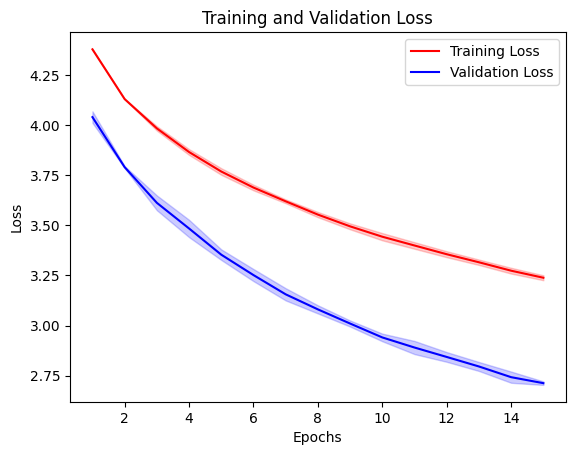

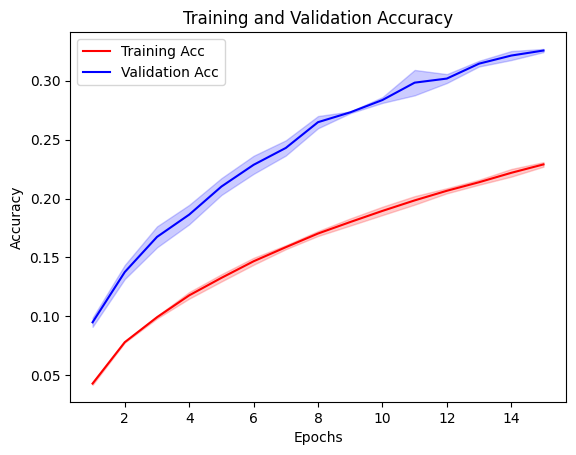

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/vit_bitlinear_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/vit_bitlinear_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
shutil.copy('/content/vit_bitlinear_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_bitlinear_loss_plot.pdf')
shutil.copy('/content/vit_bitlinear_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_bitlinear_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_bitblas/vit_bitblas_bitlinear_accuracy_plot.pdf'

In [ ]:
# NUM_EVAL_RUNS = 1

# BitLinear inference
eval_times_bitlinear = []
eval_losses_bitlinear = []
eval_accs_bitlinear = []
eval_latencies_bitlinear = []
eval_throughputs_bitlinear = []

for run in range(NUM_EVAL_RUNS):
    bitlinear_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    bitlinear_model.head = BitLinear(192, 112, bias=False)
    for block in bitlinear_model.blocks:
        block.attn.qkv = BitLinear(192, 576, bias=False)
        block.attn.proj = BitLinear(192, 192, bias=False)
        block.mlp.fc1 = BitLinear(192, 768, bias=False)
        block.mlp.fc2 = BitLinear(768, 192, bias=False)
    bitlinear_model.forward = types.MethodType(new_forward, bitlinear_model)
    bitlinear_model.load_state_dict(torch.load(f'/content/unquantized_run{run}.pth'),strict=False)
    bitlinear_model = bitlinear_model.to(device)
    bitlinear_model.eval()

    if run == 0:
        warmup_gpu(bitlinear_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'BitLinear Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_bitlinear.append(run_time)
    eval_losses_bitlinear.append(test_loss / len(test_loader))
    eval_accs_bitlinear.append(test_correct_predictions / test_total)
    eval_latencies_bitlinear.append(run_time / len(test_loader) * 1000)
    eval_throughputs_bitlinear.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_bitlinear[-1]:.4f}, Accuracy={eval_accs_bitlinear[-1]:.4f}, Latency={eval_latencies_bitlinear[-1]:.2f}ms, Throughput={eval_throughputs_bitlinear[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BITLINEAR INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_bitlinear):.2f}s ± {np.std(eval_times_bitlinear):.2f}s")
print(f"Loss:       {np.mean(eval_losses_bitlinear):.4f} ± {np.std(eval_losses_bitlinear):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_bitlinear):.4f} ± {np.std(eval_accs_bitlinear):.4f}")
print(f"Latency:    {np.mean(eval_latencies_bitlinear):.2f}ms ± {np.std(eval_latencies_bitlinear):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_bitlinear):.2f} ± {np.std(eval_throughputs_bitlinear):.2f} samples/s")

GPU warmup complete (5 batches)


BitLinear Testing run 1/3: 100%|██████████| 40/40 [00:07<00:00,  5.03it/s]


Run 1: Time=7.96s, Loss=2.5371, Accuracy=0.3654, Latency=198.92ms, Throughput=628.39 samples/s


BitLinear Testing run 2/3: 100%|██████████| 40/40 [00:05<00:00,  6.87it/s]


Run 2: Time=5.82s, Loss=2.5333, Accuracy=0.3788, Latency=145.61ms, Throughput=858.48 samples/s


BitLinear Testing run 3/3: 100%|██████████| 40/40 [00:05<00:00,  6.87it/s]

Run 3: Time=5.83s, Loss=2.5427, Accuracy=0.3648, Latency=145.65ms, Throughput=858.22 samples/s

BITLINEAR INFERENCE SUMMARY (3 runs)
Time:       6.54s ± 1.00s
Loss:       2.5377 ± 0.0039
Accuracy:   0.3697 ± 0.0065
Latency:    163.39ms ± 25.12ms
Throughput: 781.70 ± 108.40 samples/s


In [ ]:
# Quantization


for run in range(NUM_RUNS):
    print(f"Quantizing run {run}...")
    checkpoint = torch.load(f'/content/unquantized_run{run}.pth', map_location='cpu', mmap=True)

    # strip torch.compile's _orig_mod. prefix
    checkpoint = {k.replace('_orig_mod.', ''): v for k, v in checkpoint.items()}

    int2_res = {}
    for key, value in checkpoint.items():
        if 'weight' in key and value.dim() == 2:
            scale = 1.0 / value.abs().mean().clamp(min=1e-5)
            weight_int8 = (value * scale).round().clamp(-1, 1).to(torch.int8)

            n, k = value.shape
            if (n, k) in bitblas_matmuls:
                ref_matmul = next(iter(bitblas_matmuls[(n, k)].values()))
                weight_transformed = ref_matmul.transform_weight(weight_int8.cuda()).cpu()
            else:
                weight_transformed = weight_int8

            int2_res[key] = weight_transformed
            int2_res[key.replace('weight', 'weight_scale')] = torch.tensor([1.0 / scale])
        else:
            int2_res[key] = value.clone()

    torch.save(int2_res, f'/content/quantized_run{run}.pth')
    print(f"  Saved to quantized_run{run}.pth")

print("All runs quantized")



Quantizing run 0...
  Saved to quantized_run0.pth
Quantizing run 1...
  Saved to quantized_run1.pth
Quantizing run 2...
  Saved to quantized_run2.pth
All runs quantized


In [ ]:
import shutil
import os

save_dir = '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ViT/BitBlas'
os.makedirs(save_dir, exist_ok=True)

for run in range(NUM_RUNS):
    for name in ['unquantized', 'quantized', 'baseline']:
        src = f'/content/{name}_run{run}.pth'
        if os.path.exists(src):
            shutil.copy(src, f'{save_dir}/{name}_run{run}.pth')
            print(f"Saved {name}_run{run}.pth")
        else:
            print(f"{name}_run{run}.pth not found")

print("\nAll checkpoints saved to Google Drive")

Saved unquantized_run0.pth
Saved quantized_run0.pth
Saved baseline_run0.pth
Saved unquantized_run1.pth
Saved quantized_run1.pth
Saved baseline_run1.pth
Saved unquantized_run2.pth
Saved quantized_run2.pth
Saved baseline_run2.pth

All checkpoints saved to Google Drive


In [ ]:

import torch
import timm
import time
from tqdm import tqdm
import numpy as np


NUM_EVAL_RUNS = 3

eval_times_kernel = []
eval_losses_kernel = []
eval_accs_kernel = []
eval_latencies_kernel = []
eval_throughputs_kernel = []

loss_fn = torch.nn.CrossEntropyLoss()

for run in range(NUM_EVAL_RUNS):
    inference_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    inference_model.head = BitLinearKernel(192, 112, bias=False)
    for block in inference_model.blocks:
        block.attn.qkv = BitLinearKernel(192, 576, bias=False)
        block.attn.proj = BitLinearKernel(192, 192, bias=False)
        block.mlp.fc1 = BitLinearKernel(192, 768, bias=False)
        block.mlp.fc2 = BitLinearKernel(768, 192, bias=False)
    inference_model.forward = types.MethodType(new_forward, inference_model)
    inference_model = inference_model.to(device)
    inference_model.load_state_dict(torch.load(f'/content/quantized_run{run}.pth'), strict=False)
    inference_model.eval()

    if run == 0:
        warmup_gpu(inference_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Kernel Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = inference_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_kernel.append(run_time)
    eval_losses_kernel.append(test_loss / len(test_loader))
    eval_accs_kernel.append(test_correct_predictions / test_total)
    eval_latencies_kernel.append(run_time / len(test_loader) * 1000)
    eval_throughputs_kernel.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_kernel[-1]:.4f}, Accuracy={eval_accs_kernel[-1]:.4f}, Latency={eval_latencies_kernel[-1]:.2f}ms, Throughput={eval_throughputs_kernel[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"INFERENCE KERNEL SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_kernel):.2f}s ± {np.std(eval_times_kernel):.2f}s")
print(f"Loss:       {np.mean(eval_losses_kernel):.4f} ± {np.std(eval_losses_kernel):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_kernel):.4f} ± {np.std(eval_accs_kernel):.4f}")
print(f"Latency:    {np.mean(eval_latencies_kernel):.2f}ms ± {np.std(eval_latencies_kernel):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_kernel):.2f} ± {np.std(eval_throughputs_kernel):.2f} samples/s")

GPU warmup complete (5 batches)


Kernel Testing run 1/3: 100%|██████████| 40/40 [00:27<00:00,  1.47it/s]


Run 1: Time=27.30s, Loss=2.5373, Accuracy=0.3654, Latency=682.45ms, Throughput=183.16 samples/s


Kernel Testing run 2/3: 100%|██████████| 40/40 [00:26<00:00,  1.50it/s]


Run 2: Time=26.64s, Loss=2.5333, Accuracy=0.3776, Latency=665.93ms, Throughput=187.71 samples/s


Kernel Testing run 3/3: 100%|██████████| 40/40 [00:26<00:00,  1.51it/s]

Run 3: Time=26.49s, Loss=2.5431, Accuracy=0.3644, Latency=662.35ms, Throughput=188.72 samples/s

INFERENCE KERNEL SUMMARY (3 runs)
Time:       26.81s ± 0.35s
Loss:       2.5379 ± 0.0040
Accuracy:   0.3691 ± 0.0060
Latency:    670.24ms ± 8.75ms
Throughput: 186.53 ± 2.42 samples/s


In [ ]:
# parameter counts, size on disk
def model_stats(model, filepath):
    # parameter count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # size on disk
    torch.save(model.state_dict(), filepath)
    size_mb = os.path.getsize(filepath) / 1024**2

    print(f"Total parameters:     {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Size on disk:         {size_mb:.2f} MB")

model_stats(baseline_model, '/content/baseline_run0.pth')
model_stats(bitlinear_model, '/content/unquantized_run0.pth')
model_stats(inference_model, '/content/quantized_run0.pth')

Total parameters:     5,546,032
Trainable parameters: 5,546,032
Size on disk:         21.21 MB
Total parameters:     5,525,184
Trainable parameters: 5,525,184
Size on disk:         21.12 MB
Total parameters:     1,527,793
Trainable parameters: 195,264
Size on disk:         2.07 MB
